# EDA and Data Preparation

## Analysis Goal

- country
- year
- house_price_index
- rent_price_index
- house_price_to_income_ratio
- housing_cost_overburden_rate
- fertility_rate
- life_satisfaction
- living_with_parents
- net_migration_rate
- population

In [1953]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


## Data Understanding


### Data Collection


#### Load data

In [1954]:
def read_tsv(file, keep=None):
    df = pd.read_csv(f'eurostat_data/{file}', sep='\t', na_values=[':', ': ', ': @N'])
    first_column = df.columns[0]
    cols = first_column.replace('\\TIME_PERIOD', '').split(',')

    df[cols] = df[first_column].str.split(',', expand=True)
    df = df.drop(columns=first_column)
    
    df = df.rename(columns={'geo': 'country'})
    keep = keep or []

    cols = [col for col in df.columns if (col not in cols and col != 'country')]
    df[cols] = df[cols].replace(r'\s*[A-Za-z]+$', '', regex=True)
    df[cols] = df[cols].replace(['', ':', ': ', ': @N'], pd.NA)
    df[cols] = df[cols].apply(pd.to_numeric)

    ordered_cols = ['country'] + keep + cols
    return df[ordered_cols]

In [1955]:
house_price_df = read_tsv('house.tsv')
rent_price_df = read_tsv('rent.tsv')
price_to_income_df = read_tsv('income.tsv')
housing_burden_df = read_tsv('burden.tsv')
population_df =  read_tsv('population.tsv')
migration_df = read_tsv('migration.tsv')
lifesatisfaction_df = read_tsv('lifesatisfaction.tsv')
withparents_df = read_tsv('withparents.tsv')
fertility_df = read_tsv('child.tsv', keep=['indic_de'])

In [1956]:
house_price_df.head()

,country,2005,2006,2007,2008,2009,2010,2011,2012,2013,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AT,NaN,NaN,NaN,NaN,NaN,77.32,81.47,86.86,91.20,...,106.71,112.14,118.83,125.97,135.52,151.02,168.49,163.68,163.06,167.33
1,BE,72.85,80.00,86.20,89.95,89.58,91.60,94.88,97.11,98.55,...,102.33,105.95,109.15,113.23,118.09,125.96,132.93,136.05,140.42,144.86
2,BG,80.09,91.86,118.42,147.97,117.79,105.81,99.98,98.07,95.92,...,107.02,116.30,123.96,131.42,137.41,149.33,169.92,186.67,217.47,249.23
3,CY,97.06,108.57,121.32,128.17,119.76,112.90,111.09,107.70,103.29,...,99.82,104.48,103.08,111.70,117.49,115.70,123.22,134.60,144.46,150.89
4,CZ,NaN,NaN,NaN,100.80,96.90,95.20,95.30,93.90,93.90,...,107.20,119.70,130.00,141.90,153.90,184.20,215.30,211.70,222.30,245.40


In [1957]:
rent_price_df.head()

,country,1996-01,1996-02,1996-03,1996-04,1996-05,1996-06,1996-07,1996-08,1996-09,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,117.03,118.15,118.68,120.01,120.78,121.45,123.14,123.18,123.20,125.34
1,AT,54.21,54.32,54.43,54.60,54.77,54.99,55.43,55.93,56.43,...,145.20,145.57,145.83,146.43,147.52,148.16,148.96,149.97,149.87,149.84
2,BE,72.42,72.42,72.35,72.42,72.50,72.50,72.50,72.50,72.57,...,128.77,128.85,129.64,130.34,130.24,130.65,130.50,132.39,132.37,132.91
3,BG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,144.11,145.75,145.74,146.87,149.45,152.07,152.30,153.60,153.76,153.92
4,CH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,112.90,113.03,113.36,113.49,113.62,114.04,114.16,114.27,114.17,114.31


In [1958]:
price_to_income_df.head()

,country,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AT,86.02,85.83,85.08,82.51,78.99,85.87,85.37,84.89,83.25,...,100.00,103.89,106.92,109.83,114.07,121.91,128.75,132.93,121.77,113.29
1,BE,71.54,71.85,75.11,78.82,83.63,91.59,96.17,99.29,98.47,...,100.00,99.89,100.21,100.24,100.39,103.29,104.36,101.34,96.43,96.95
2,BG,131.99,118.71,93.96,98.39,132.95,163.46,164.72,189.34,192.83,...,100.00,101.50,101.65,96.34,95.78,98.18,95.34,91.00,86.60,78.64
3,CY,96.87,93.09,96.77,99.86,100.20,100.75,106.15,113.08,108.47,...,100.00,95.76,95.42,89.35,88.50,91.53,85.81,86.93,89.67,90.20
4,CZ,90.68,92.34,98.03,102.98,98.01,96.00,96.49,109.00,114.00,...,100.00,103.13,106.93,107.94,110.19,112.36,122.58,131.30,119.31,119.40


In [1959]:
housing_burden_df.head()

,country,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.20,6.00,5.50,3.80,3.30,2.80,2.10,NaN,NaN
1,AT,NaN,7.90,4.60,5.00,5.40,8.50,8.00,7.50,7.80,...,7.20,7.10,6.80,7.00,6.30,6.10,7.40,6.00,6.30,6.50
2,BE,NaN,12.60,8.60,9.80,10.10,12.50,8.70,8.90,10.60,...,9.80,9.40,8.90,8.40,7.70,7.60,7.50,7.80,6.70,6.70
3,BG,NaN,NaN,NaN,15.40,21.20,13.30,7.00,5.90,8.70,...,20.70,18.90,17.90,16.00,14.40,11.60,15.10,11.10,8.00,6.90
4,CH,NaN,NaN,NaN,NaN,NaN,NaN,13.20,14.10,13.10,...,12.00,12.70,12.80,14.20,13.60,14.80,13.40,14.20,15.30,NaN


In [1960]:
population_df.head()

,country,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,76177.00,NaN,NaN,NaN,NaN,NaN,NaN
1,AL,1583800.00,1633800.00,1685800.00,1736838.00,1788404.00,1839866.00,1889715.00,1939430.00,1991765.00,...,2875592.00,2876591.00,2870324.00,2862427.00,2845955.00,2829741.00,2793592.00,2761785.00,NaN,2363314.00
2,AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2998577.00,2986151.00,2972732.00,2965269.00,2959694.00,2963251.00,NaN,2977130.00,2991201.00,NaN
3,AT,7030385.00,7064693.00,7107904.00,7151824.00,7199798.00,7247804.00,7293973.00,7350159.00,7403837.00,...,8700471.00,8772865.00,8822267.00,8858775.00,8901064.00,8932664.00,8978929.00,9104772.00,9158750.00,9197213.00
4,AZ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,9705643.00,9809981.00,9898085.00,9981457.00,10067108.00,10119133.00,10156366.00,10127145.00,10180770.00,10224889.00


In [1961]:
migration_df.head()

,country,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,14.50,NaN,15.60,14.70,NaN,NaN,23.90,40.90,NaN,NaN
1,AL,-1.80,-0.60,1.30,0.10,-0.70,0.50,0.60,-0.20,2.60,...,-3.20,-5.20,-5.20,-8.10,-5.90,-11.70,-11.70,-144.80,-12.10,NaN
2,AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-8.30,-8.00,-6.20,-5.20,1.10,NaN,NaN,0.60,25.30,NaN
3,AT,-0.30,-0.40,0.20,0.70,0.40,1.40,2.60,2.90,-0.90,...,7.50,5.10,4.00,4.60,4.40,5.80,15.10,7.20,5.40,NaN
4,AZ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.20,0.10,0.20,0.00,0.10,0.20,-9.00,0.10,0.10,NaN


In [1962]:
lifesatisfaction_df.head()

,country,2013,2018,2021,2022,2023,2024,2025
0,AL,NaN,5.50,5.70,6.00,6.30,NaN,NaN
1,AT,7.80,8.00,8.00,7.90,7.70,7.60,7.70
2,BE,7.50,7.60,7.50,7.60,7.70,7.60,7.60
3,BG,4.80,5.40,5.70,5.60,5.90,6.20,6.30
4,CH,8.00,8.00,7.90,8.00,7.80,7.70,NaN


In [1963]:
withparents_df.head()

,country,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,72.70,74.50,71.30,75.30,76.80,76.10,76.40,NaN,NaN
1,AT,42.30,40.30,44.50,45.80,47.00,46.00,47.40,46.90,46.50,...,42.60,42.10,40.90,42.60,40.40,37.70,38.60,40.00,39.00,40.30
2,BE,38.10,38.50,39.30,42.50,41.50,42.20,41.40,39.50,40.90,...,47.30,47.20,48.50,47.50,48.20,47.10,45.30,46.30,48.30,51.40
3,BG,NaN,NaN,58.10,58.10,59.70,62.70,62.80,66.00,66.70,...,58.90,58.40,59.10,59.20,59.30,60.10,59.60,59.70,58.70,57.80
4,CH,NaN,NaN,NaN,NaN,36.90,41.10,41.20,43.50,42.90,...,39.30,37.90,42.10,38.90,38.60,38.50,38.00,40.60,42.40,NaN


In [1964]:
fertility_df.head()

,country,indic_de,1960,1961,1962,1963,1964,1965,1966,1967,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AD,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AL,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,27.90,28.20,28.40,28.60,NaN,29.00,29.20,29.50,NaN,29.60
2,AM,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,26.80,27.00,27.00,27.10,27.30,NaN,NaN,NaN,NaN,NaN
3,AT,AGEMOTH,27.60,27.50,27.50,27.40,27.40,27.30,27.10,27.00,...,30.60,30.60,30.70,30.90,31.00,31.00,31.20,31.20,31.20,31.20
4,AZ,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,25.60,25.50,25.60,25.60,25.60,NaN,NaN,NaN,NaN,NaN


In [1965]:
fertility_df.tail()

,country,indic_de,1960,1961,1962,1963,1964,1965,1966,1967,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
93,SM,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
94,TR,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.14,2.11,2.07,1.99,1.88,NaN,NaN,1.63,1.51,1.48
95,UA,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.36,1.35,1.26,1.20,1.14,NaN,NaN,NaN,NaN,NaN
96,UK,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.80,1.79,1.74,1.68,NaN,NaN,NaN,NaN,NaN,NaN
97,XK,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.66,1.65,1.61,1.55,NaN,NaN,NaN,NaN,NaN


####  Transform dataframe format

In [1966]:
def transform_to_long(df, name, indicator_col=None):
    value_per_year = []
    for col in df.columns:
        column_string = str(col).strip()
        if column_string.isdigit():
            value_per_year.append(col)


    id_cols = ['country']
    if indicator_col is not None:
        id_cols.append(indicator_col)

    long_df = df.melt(
        id_vars=id_cols,
        value_vars=value_per_year,
        var_name='year',
        value_name=name
    )

    if indicator_col is not None:
        long_df = long_df.pivot_table(
            index=['country', 'year'],
            columns=indicator_col,
            values=name,
            aggfunc='first'
        ).reset_index()

        long_df = long_df.rename(columns = { 'AGEMOTH': 'mean_childbirth_age',  
                                            'TOTFERRT': 'fertility_rate'})
        

    return long_df


In [1967]:
def transform_to_long_and_yearly(df):

    value_per_month = []
    for col in df.columns:
        if '-' in str(col):
            value_per_month.append(col)

    rent_long = df.melt(
        id_vars=['country'],
        value_vars=value_per_month,
        var_name='month',
        value_name='rent_price_index'
    )

    rent_long['year'] = rent_long['month'].str[:4]

    rent_yearly = (
        rent_long
        .groupby(['country', 'year'], as_index=False)['rent_price_index']
        .mean()
    )

    return rent_yearly

In [1968]:
income_long = transform_to_long(price_to_income_df, 'house_price_to_income_index')
burden_long = transform_to_long(housing_burden_df, 'housing_overburden')
house_price_long =transform_to_long(house_price_df, 'house_price_index')
population_long = transform_to_long(population_df, 'population')
migration_long = transform_to_long(migration_df, 'net_migration')
lifesatisfaction_long = transform_to_long(lifesatisfaction_df, 'life_satisfaction')
withparents_long = transform_to_long(withparents_df, 'living_with_parents')
fertility_long = transform_to_long(fertility_df, 'value', indicator_col='indic_de')
rent_long = transform_to_long_and_yearly(rent_price_df)


#### Standardize the date range

In [1969]:
print(f'House price to income ratio: {min(income_long['year'])}- {max(income_long['year'])}')
print(f'Housing overburden: {min(burden_long['year'])}- {max(burden_long['year'])}')
print(f'House price index: {min(house_price_long['year'])}- {max(house_price_long['year'])}')
print(f'Rent price index: {min(rent_long['year'])}- {max(rent_long['year'])}')

print(f'Population: {min(population_long['year'])}- {max(population_long['year'])}')
print(f'Net migration: {min(migration_long['year'])}- {max(migration_long['year'])}')
print(f'Living with parents: {min(withparents_long['year'])}- {max(withparents_long['year'])}')
print(f'Fertility: {min(fertility_long['year'])}- {max(fertility_long['year'])}')
print(f'Life satisfaction: {min(lifesatisfaction_long['year'])}- {max(lifesatisfaction_long['year'])}')


House price to income ratio: 2000 - 2024 
Housing overburden: 2003 - 2025 
House price index: 2005 - 2025 
Rent price index: 1996- 2025
Population: 1960 - 2025 
Net migration: 1960 - 2025 
Living with parents: 2003 - 2025 
Fertility: 1960 - 2024 
Life satisfaction: 2013 - 2025 


In [1970]:
START_YEAR = 2005
END_YEAR = 2024

def filter_years(df):
    df['year'] = df['year'].astype(int)
    return df[(df['year'] >= START_YEAR) & (df['year'] <= END_YEAR)]

income_long = filter_years(income_long)
burden_long = filter_years(burden_long)
house_price_long = filter_years(house_price_long)
rent_long = filter_years(rent_long)
population_long = filter_years(population_long)
migration_long = filter_years(migration_long)
withparents_long = filter_years(withparents_long)
fertility_long = filter_years(fertility_long)
lifesatisfaction_long = filter_years(lifesatisfaction_long)

#### Merge

In [1971]:
final_raw_df = income_long.merge(burden_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(house_price_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(population_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(migration_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(lifesatisfaction_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(withparents_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(fertility_long, on=['country', 'year'], how='outer')
final_raw_df = final_raw_df.merge(rent_long, on=['country', 'year'], how='outer')

In [1972]:
final_raw_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,NaN,31.10,1.19,NaN


In [1973]:
len(final_raw_df)

1100

###  Data Description and Initial Exploration

In [1974]:
final_raw_df.shape

(1100, 12)

In [1975]:
final_raw_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,NaN,31.10,1.19,NaN


In [1976]:
final_raw_df.columns

Index(['country', 'year', 'house_price_to_income_index', 'housing_overburden',
       'house_price_index', 'population', 'net_migration', 'life_satisfaction',
       'living_with_parents', 'mean_childbirth_age', 'fertility_rate',
       'rent_price_index'],
      dtype='object')

In [1977]:
final_raw_df['year'].min(), final_raw_df['year'].max()

(np.int64(2005), np.int64(2024))

In [1978]:
final_raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   country                      1100 non-null   object 
 1   year                         1100 non-null   int64  
 2   house_price_to_income_index  540 non-null    float64
 3   housing_overburden           656 non-null    float64
 4   house_price_index            552 non-null    float64
 5   population                   974 non-null    float64
 6   net_migration                979 non-null    float64
 7   life_satisfaction            203 non-null    float64
 8   living_with_parents          666 non-null    float64
 9   mean_childbirth_age          847 non-null    float64
 10  fertility_rate               847 non-null    float64
 11  rent_price_index             727 non-null    float64
dtypes: float64(10), int64(1), object(1)
memory usage: 103.3+ KB


In [1979]:
pd.set_option('display.float_format', '{:.2f}'.format)
final_raw_df.describe()


,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
count,1100.00,540.00,656.00,552.00,974.00,979.00,203.00,666.00,847.00,847.00,727.00
mean,2014.50,108.57,9.68,122.83,33174197.23,1.72,7.07,49.92,29.81,1.56,102.02
std,5.77,19.73,6.19,92.32,88707626.25,15.52,0.70,16.03,1.60,0.22,36.69
min,2005.00,55.88,1.10,52.04,29673.00,-221.70,4.80,0.00,25.50,1.01,38.64
25%,2009.75,98.31,5.50,95.31,2796693.50,-0.30,6.70,39.23,28.80,1.39,90.92
50%,2014.50,104.45,8.50,107.25,7350222.00,1.80,7.20,52.55,30.10,1.52,100.00
75%,2019.25,114.38,11.93,132.24,17756136.25,5.30,7.60,61.20,31.00,1.71,107.69
max,2024.00,263.14,45.50,1721.53,519826027.00,51.90,8.10,79.90,33.20,2.23,879.78


In [1980]:
final_raw_df['country'].nunique()

55

In [1981]:
values_per_year = final_raw_df['year'].value_counts().sort_index()
pd.DataFrame(values_per_year)


,count
year,
2005,55
2006,55
2007,55
2008,55
2009,55
2010,55
2011,55
2012,55
2013,55


In [1982]:
values_per_country = final_raw_df['country'].value_counts().head(10)
pd.DataFrame(values_per_country)

,count
country,
AD,20
AL,20
AM,20
AT,20
AZ,20
BA,20
BE,20
BG,20
BY,20


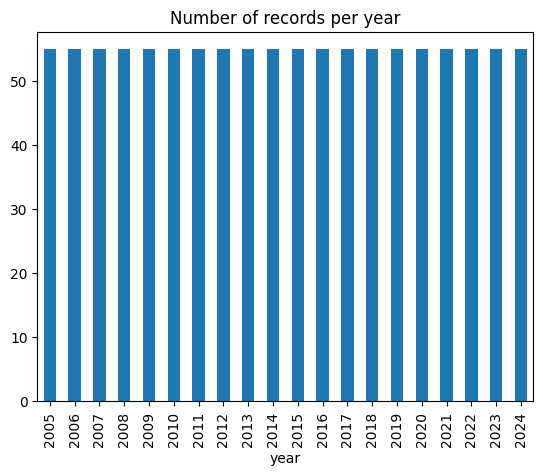

In [1983]:
final_raw_df.groupby('year').size().plot(kind='bar')
plt.title('Number of records per year')
plt.show()

### Data Quality Assessment

In [1984]:
def show_missing_values(df):
    coverage = pd.DataFrame({
        'missing_count': df.isna().sum(),
        'missing_percent': df.isna().mean() * 100,
        'present_count': df.notna().sum()
    }).sort_values('missing_percent', ascending=False)

    return coverage

show_missing_values(final_raw_df)

,missing_count,missing_percent,present_count
life_satisfaction,897,81.55,203
house_price_to_income_index,560,50.91,540
house_price_index,548,49.82,552
housing_overburden,444,40.36,656
living_with_parents,434,39.45,666
rent_price_index,373,33.91,727
mean_childbirth_age,253,23.00,847
fertility_rate,253,23.00,847
population,126,11.45,974
net_migration,121,11.00,979


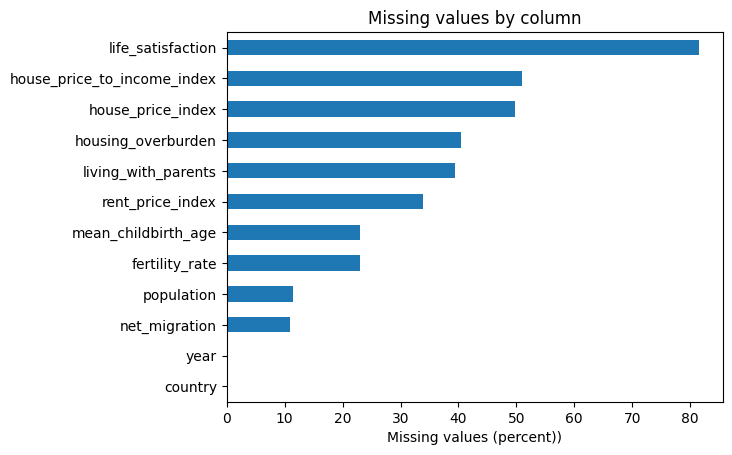

In [1985]:
missing_percent = (final_raw_df.isna().mean() * 100).sort_values(ascending=True)

missing_percent.plot(kind='barh')
plt.xlabel('Missing values (percent))')
plt.title('Missing values by column')
plt.show()

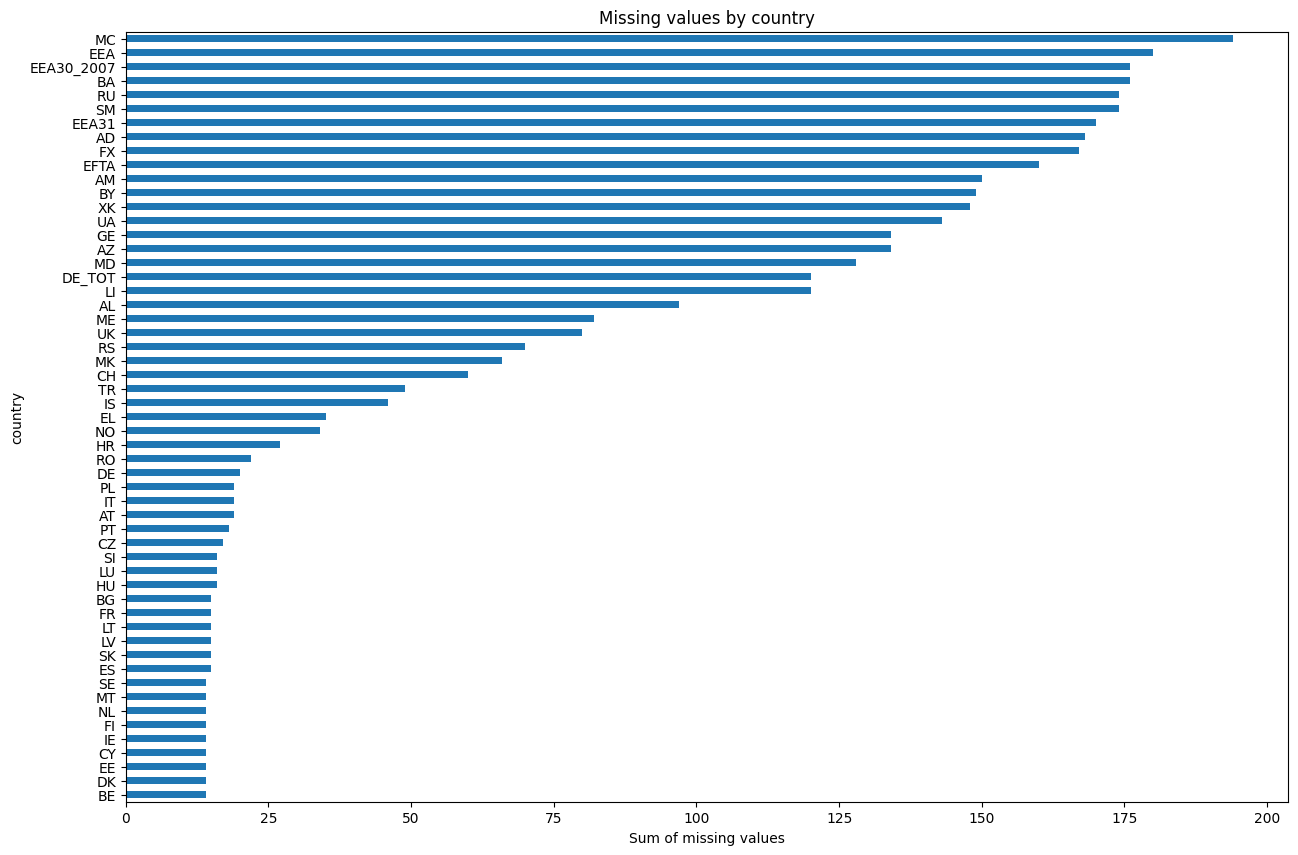

In [1986]:

indicator_cols = [col for col in final_raw_df.columns if col not in ['country', 'year']]

missing_by_country = (
    final_raw_df.groupby('country')[indicator_cols]
    .apply(lambda x: x.isna().sum().sum())
    .sort_values()
)

missing_by_country.plot(kind='barh', figsize=(15,10))
plt.xlabel('Sum of missing values')
plt.title('Missing values by country')
plt.show()

In [1987]:
final_raw_df.duplicated().sum()

np.int64(0)

In [1988]:
final_raw_df.duplicated(subset=['country', 'year']).sum()

np.int64(0)

## Data Preparation

In [1989]:
final_df = final_raw_df.copy()

### Data cleaning

In [1990]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,NaN,31.10,1.19,NaN


In [1991]:
numeric_columns = final_df.select_dtypes(include='number').columns.drop('year')
invalid = {}

for col in numeric_columns:
    invalid[col] = {
        'zero_values': (final_df[col] == 0).sum(),
        'negative_values': (final_df[col]<0).sum()
    }

to_investigate_df = pd.DataFrame(invalid).T
to_investigate_df

,zero_values,negative_values
house_price_to_income_index,0,0
housing_overburden,0,0
house_price_index,0,0
population,0,0
net_migration,26,276
life_satisfaction,0,0
living_with_parents,1,0
mean_childbirth_age,0,0
fertility_rate,0,0
rent_price_index,0,0


In [1992]:
final_df[final_df['living_with_parents'] == 0]

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
1037,TR,2022,NaN,11.20,611.40,84680273.00,0.80,5.40,0.00,29.20,1.63,221.23


In [1993]:
final_df.loc[final_df['living_with_parents'] == 0, 'living_with_parents'] = pd.NA

### Missing values

In [1994]:
columns_to_verify = []
for col in final_df.columns:
    if col not in ['country', 'year']:
        columns_to_verify.append(col)

missing_percent_by_country = final_df.groupby('country')[columns_to_verify].apply(
    lambda x: x.isna().mean().mean() * 100
)
countries = missing_percent_by_country[missing_percent_by_country < 50].index
final_df = final_df[final_df['country'].isin(countries)]

In [1995]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
life_satisfaction,518,71.94,202
house_price_to_income_index,180,25.00,540
house_price_index,168,23.33,552
housing_overburden,65,9.03,655
living_with_parents,56,7.78,664
rent_price_index,23,3.19,697
mean_childbirth_age,12,1.67,708
fertility_rate,12,1.67,708
population,6,0.83,714
net_migration,5,0.69,715


In [1996]:
missing_price_to_income= final_df.groupby('country')['house_price_to_income_index'].apply(
    lambda x: x.isna().sum()
)
pd.DataFrame(missing_price_to_income[missing_price_to_income == 20])

,house_price_to_income_index
country,
AL,20
CH,20
IS,20
ME,20
MK,20
NO,20
RS,20
TR,20
UK,20


In [1997]:
countries_to_drop = missing_price_to_income[missing_price_to_income == 20].index
final_df = final_df[~final_df['country'].isin(countries_to_drop)].reset_index(drop=True)

house_price_index

In [1998]:
missing_house_price_index= final_df.groupby('country')['house_price_index'].apply(
    lambda x: x.isna().sum()
)
pd.DataFrame(missing_house_price_index[missing_house_price_index == 20])

,house_price_index
country,
EL,20


In [1999]:
countries_to_drop = missing_house_price_index[missing_house_price_index == 20].index
final_df = final_df[~final_df['country'].isin(countries_to_drop)].reset_index(drop=True)

In [2000]:
final_df['country'].nunique()

26

In [2001]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
life_satisfaction,366,70.38,154
house_price_index,38,7.31,482
housing_overburden,14,2.69,506
living_with_parents,7,1.35,513
house_price_to_income_index,0,0.00,520
year,0,0.00,520
country,0,0.00,520
population,0,0.00,520
net_migration,0,0.00,520
mean_childbirth_age,0,0.00,520


In [2002]:
columns_to_interpolate = [
    'house_price_index',
    'housing_overburden',
    'living_with_parents'
]

final_df = final_df.sort_values(['country', 'year']).reset_index(drop=True)

for column in columns_to_interpolate:
    final_df[column] = (
        final_df
        .groupby('country')[column]
        .transform(lambda x: x.interpolate(method='linear', limit_direction='both'))
    )

In [2003]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
life_satisfaction,366,70.38,154
country,0,0.00,520
house_price_to_income_index,0,0.00,520
year,0,0.00,520
housing_overburden,0,0.00,520
house_price_index,0,0.00,520
population,0,0.00,520
net_migration,0,0.00,520
living_with_parents,0,0.00,520
mean_childbirth_age,0,0.00,520


In [2004]:
life_df = final_df[final_df['year'] >= 2013]
show_missing_values(life_df)

,missing_count,missing_percent,present_count
life_satisfaction,158,50.64,154
country,0,0.00,312
house_price_to_income_index,0,0.00,312
year,0,0.00,312
housing_overburden,0,0.00,312
house_price_index,0,0.00,312
population,0,0.00,312
net_migration,0,0.00,312
living_with_parents,0,0.00,312
mean_childbirth_age,0,0.00,312


In [2005]:
life_missing_by_year = pd.DataFrame({
    'missing_count': life_df.groupby('year')['life_satisfaction'].apply(lambda x: x.isna().sum()),
    'present_count': life_df.groupby('year')['life_satisfaction'].apply(lambda x: x.notna().sum()),
    'missing_percent': life_df.groupby('year')['life_satisfaction'].apply(lambda x: x.isna().mean() * 100)
})

life_missing_by_year

,missing_count,present_count,missing_percent
year,,,
2013,0,26,0.00
2014,26,0,100.00
2015,26,0,100.00
2016,26,0,100.00
2017,26,0,100.00
2018,0,26,0.00
2019,26,0,100.00
2020,26,0,100.00
2021,2,24,7.69


### Duplicates

## Exploratory Data Analysis

In [2006]:
final_df.shape

(520, 12)

In [2007]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AT,2005,85.87,4.60,77.32,8201359.00,6.10,NaN,44.50,29.00,1.41,72.15
1,AT,2006,85.37,5.00,77.32,8254298.00,3.00,NaN,45.80,29.20,1.41,73.76
2,AT,2007,84.89,5.40,77.32,8282984.00,2.80,NaN,47.00,29.40,1.38,75.21
3,AT,2008,83.25,8.50,77.32,8307989.00,2.90,NaN,46.00,29.50,1.42,76.16
4,AT,2009,83.19,8.00,77.32,8335003.00,2.10,NaN,47.40,29.70,1.39,79.74


In [2008]:
print(f'Final set of countries: {final_df['country'].nunique()}')
print(f'Years: {final_df['year'].min()} - {final_df['year'].max()}')
print(f'Rows: {len(final_df)}')

Final set of countries: 26
Years: 2005 - 2024
Rows: 520


In [2009]:
final_df.describe()

,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,life_satisfaction,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
count,520.00,520.00,520.00,520.00,520.00,520.00,154.00,520.00,520.00,520.00,520.00
mean,2014.50,108.51,8.29,117.35,16609375.82,3.60,7.22,49.88,30.15,1.53,100.83
std,5.77,20.03,4.25,33.32,21998031.54,7.60,0.53,14.87,1.33,0.20,19.17
min,2005.00,55.88,1.10,52.04,402668.00,-25.20,4.80,15.50,25.90,1.01,38.64
25%,2009.75,98.28,5.00,97.19,2942557.50,-0.10,7.00,41.75,29.40,1.38,90.85
50%,2014.50,104.20,7.70,107.52,7944966.00,2.60,7.30,52.80,30.35,1.50,100.00
75%,2019.25,113.98,10.30,131.28,16847148.25,5.93,7.60,60.60,31.10,1.66,108.45
max,2024.00,263.14,24.20,309.86,83456045.00,42.10,8.10,78.20,33.20,2.06,187.10


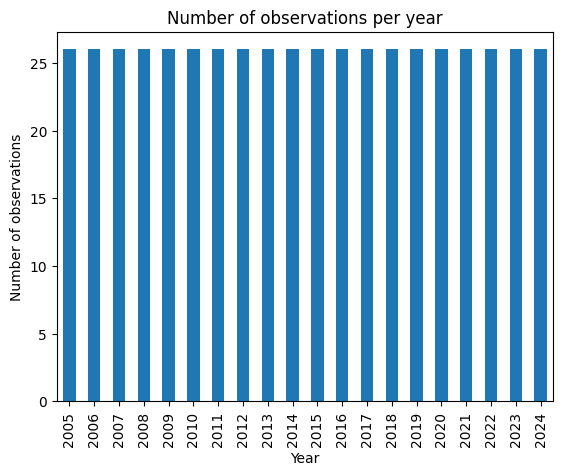

In [2010]:
final_df.groupby('year').size().plot(kind='bar')
plt.title('Number of observations per year')
plt.xlabel('Year')
plt.ylabel('Number of observations')
plt.show()

In [2011]:
indicator_cols = [col for col in final_df.columns if col not in ['country', 'year', 'life_satisfaction']]

### Univariate Analysis (Distributions)

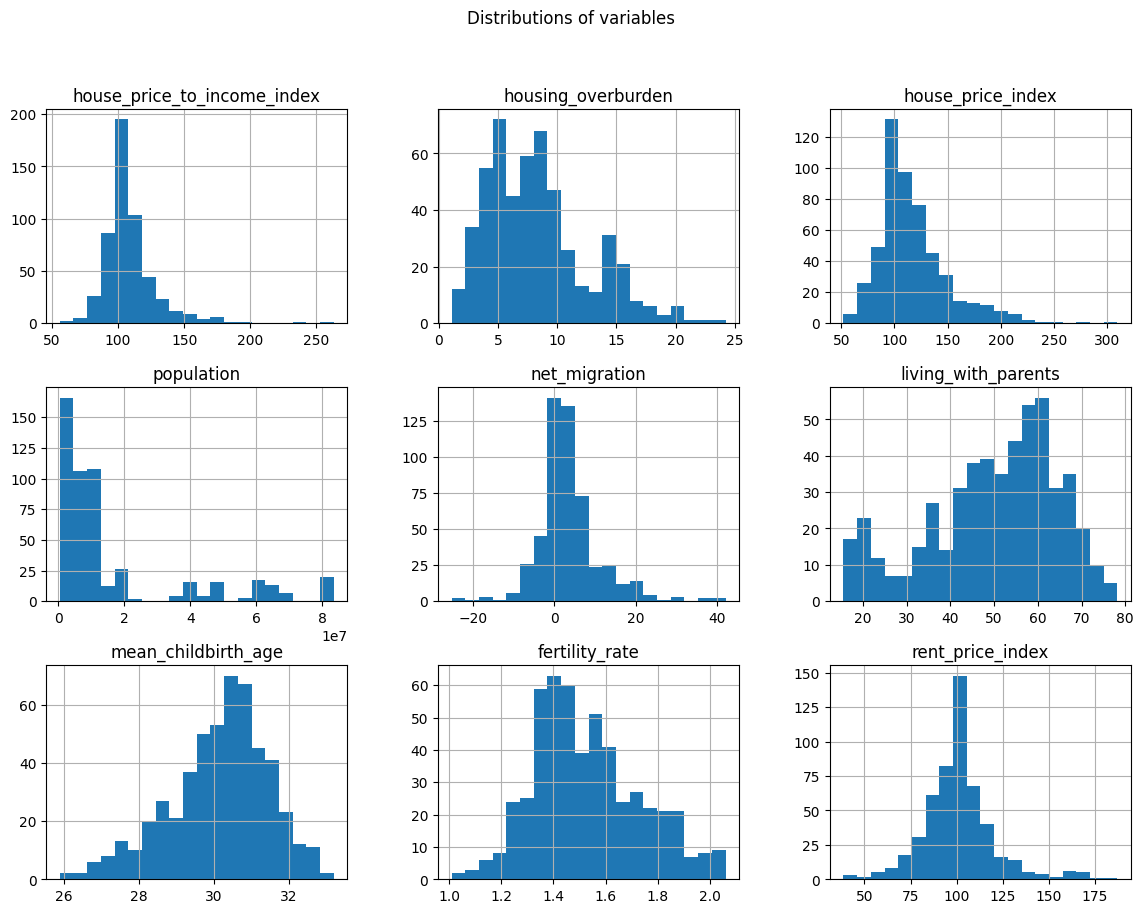

In [2012]:
final_df[indicator_cols].hist(bins=20, figsize=(14, 10))
plt.suptitle('Distributions of variables')
plt.show()

 ### Trends Analysis

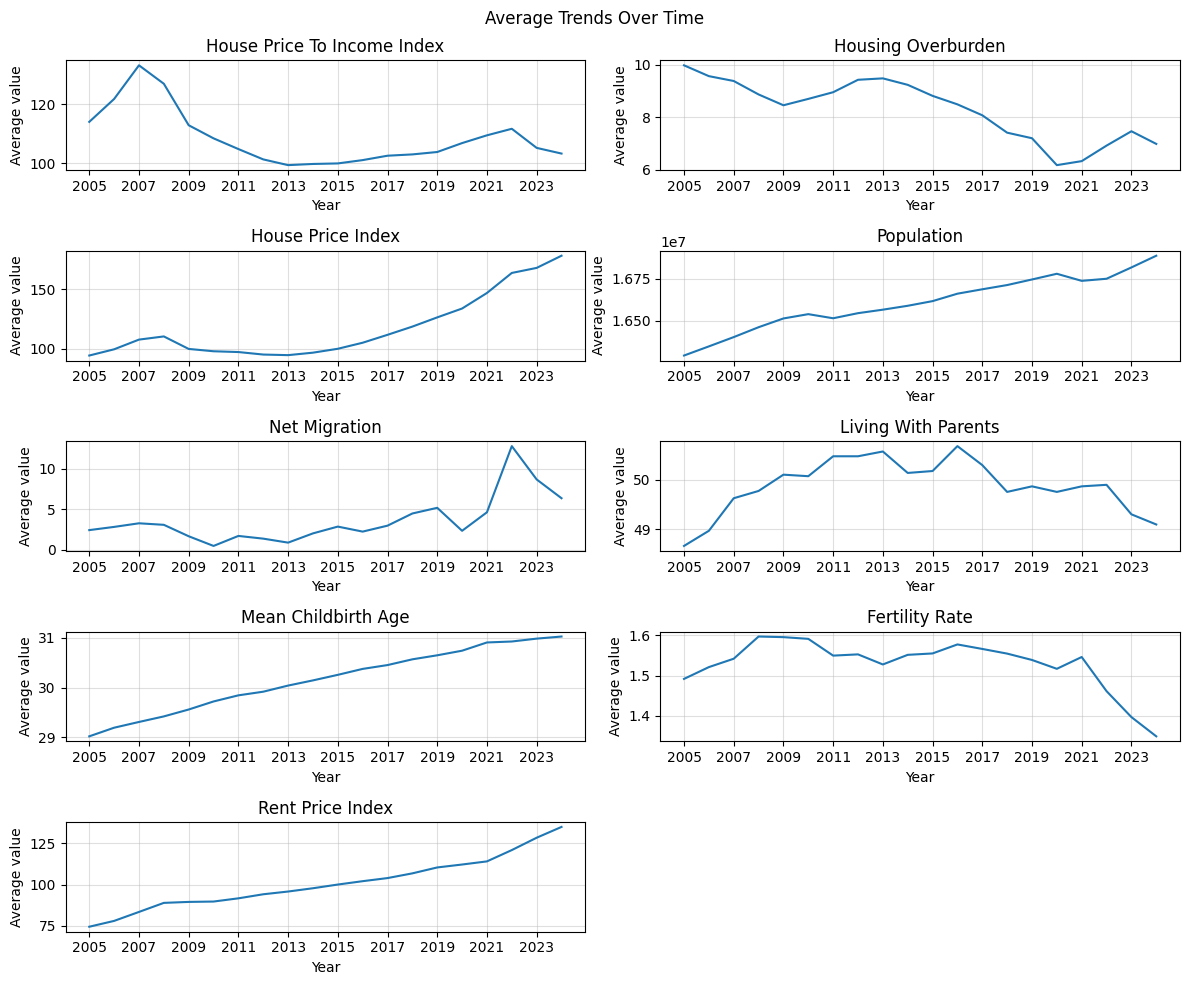

In [2013]:
yearly_avg = final_df.groupby('year')[indicator_cols].mean()
fig, axes  = plt.subplots(5,2, figsize=(12,10))
axes = axes.flatten()

for i, column in enumerate(indicator_cols):
    ax = axes[i]

    ax.plot(
        yearly_avg.index.astype(int),
        yearly_avg[column],
    )
    
    ax.set_title(column.replace('_', ' ').title())
    ax.set_xlabel('Year')
    ax.set_xticks(yearly_avg.index[::2])
    ax.set_ylabel('Average value')
    ax.grid(alpha=0.4)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Average Trends Over Time')
plt.tight_layout()
plt.show()

In [2014]:
main_variables_trends = (
    final_df.groupby('year')[
        ['house_price_index',
         'rent_price_index',
         'house_price_to_income_index']
    ]
).mean()

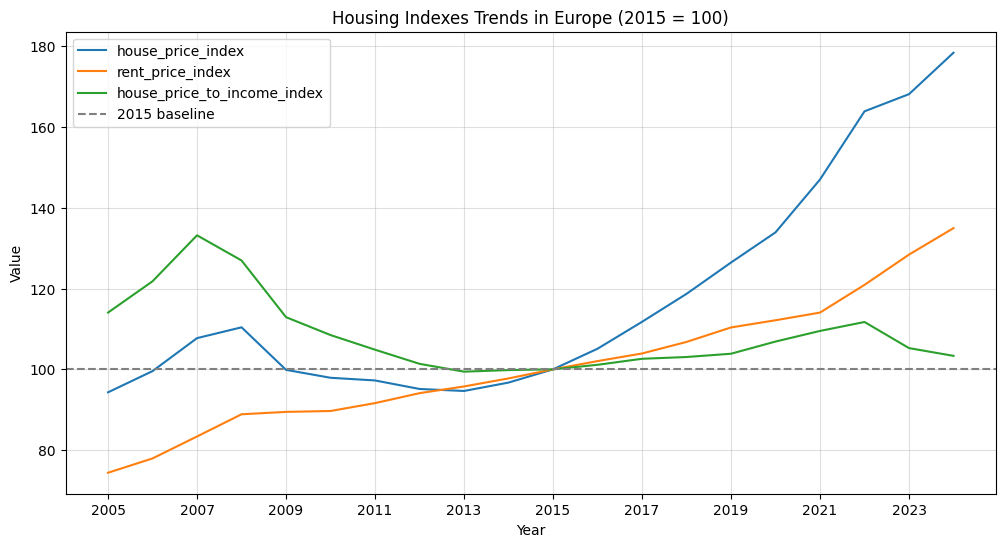

In [2015]:
plt.figure(figsize=(12,6))
for column in main_variables_trends.columns:
    plt.plot(main_variables_trends.index, main_variables_trends[column], label=column)
plt.axhline(100, color='gray', linestyle='--', label='2015 baseline')
plt.title('Housing Indexes Trends in Europe (2015 = 100)')
plt.xlabel('Year')
plt.xticks(main_variables_trends.index[::2])
plt.ylabel('Value')
plt.legend()
plt.grid(alpha=0.4)

plt.show()

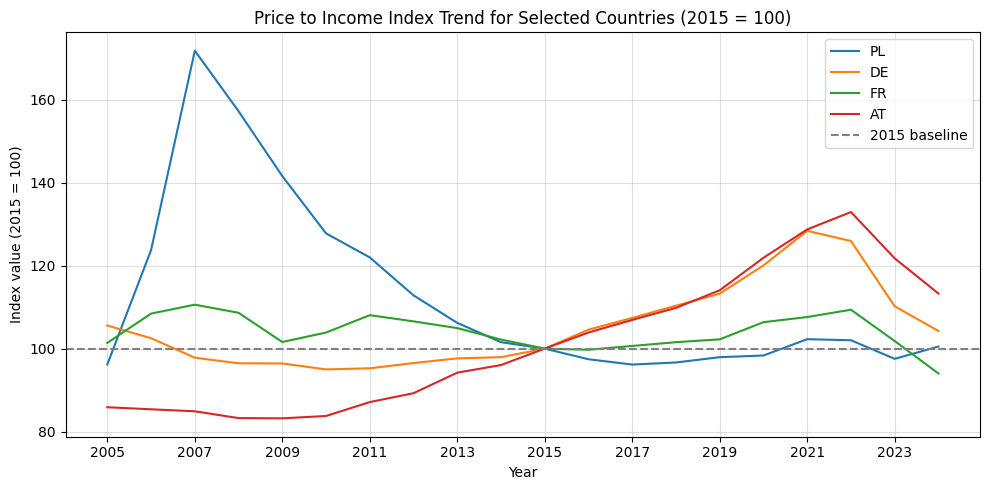

In [ ]:
selected_countries = ['PL', 'DE', 'FR', 'AT']

plt.figure(figsize=(10,5))
for country in selected_countries:
    country_data = final_df.loc[final_df['country'] == country]
    plt.plot(country_data['year'], country_data['house_price_to_income_index'], label=country)
    
plt.axhline(100, color='gray', linestyle='--', label='2015 baseline')
plt.xlabel('Year')
plt.xticks(sorted(final_df['year'].unique())[::2])
plt.ylabel('Index value (2015 = 100)')
plt.title('House price to Income Index Trend for Selected Countries (2015 = 100)')
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()


plt.show()

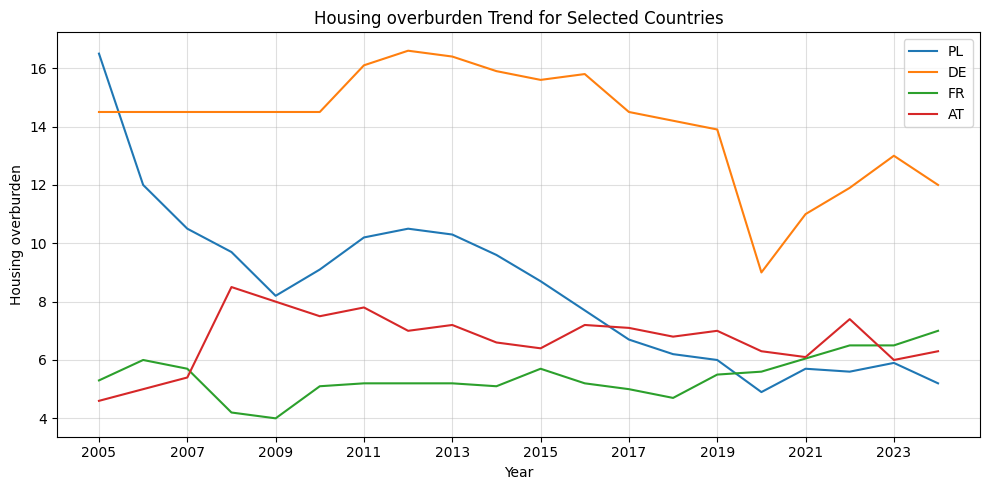

In [2017]:
plt.figure(figsize=(10,5))
for country in selected_countries:
    country_data = final_df.loc[final_df['country'] == country]
    plt.plot(country_data['year'], country_data['housing_overburden'], label=country)
    
plt.xlabel('Year')
plt.xticks(sorted(final_df['year'].unique())[::2])
plt.ylabel('Housing overburden')
plt.title('Housing overburden Trend for Selected Countries')
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()


plt.show()

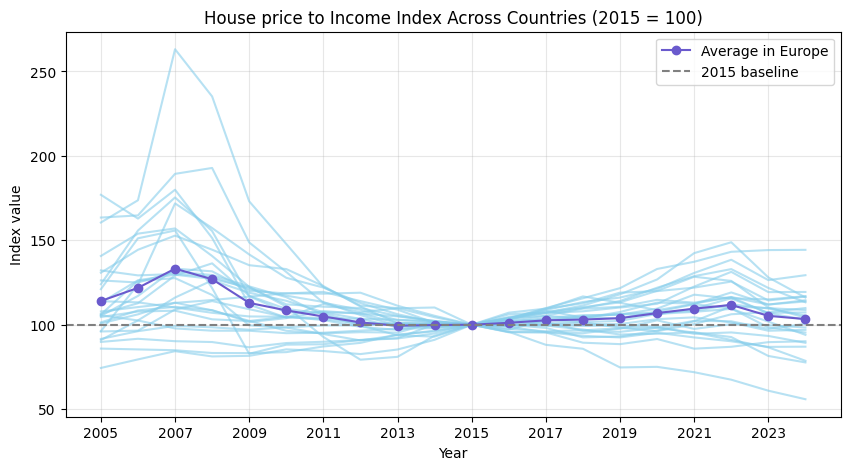

In [2018]:
main_column = 'house_price_to_income_index'
yearly_avg= final_df.groupby('year')[main_column].mean()

plt.figure(figsize=(10, 5))

for country in final_df['country'].unique():
    country_data = final_df.loc[final_df['country'] == country]
    plt.plot(
        country_data['year'],
        country_data[main_column],
        color='skyblue',
        alpha=0.6
    )

plt.plot(
    yearly_avg.index,
    yearly_avg,
    color= 'slateblue',
    marker = 'o',
    label='Average in Europe'
)

plt.axhline(100, color='gray', linestyle='--', label='2015 baseline')
plt.title('House price to Income Index Across Countries (2015 = 100)')
plt.xlabel('Year')
plt.ylabel('Index value')
plt.xticks(sorted(final_df['year'].unique())[::2])
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [2019]:
def create_change(df, main_column):
    base_year = 2015
    latest_year = 2024

    base_data = df[df['year'] == base_year][['country', main_column]]
    latest_data = df[df['year'] == latest_year][['country', main_column]]
    change_df = base_data.merge(latest_data, on= 'country', suffixes=('_2015', '_2024'))
    change_df['value_change'] = change_df[f'{main_column}_{latest_year}'] - change_df[f'{main_column}_{base_year}']

    change_df_sorted = change_df.sort_values('value_change')
    return change_df_sorted

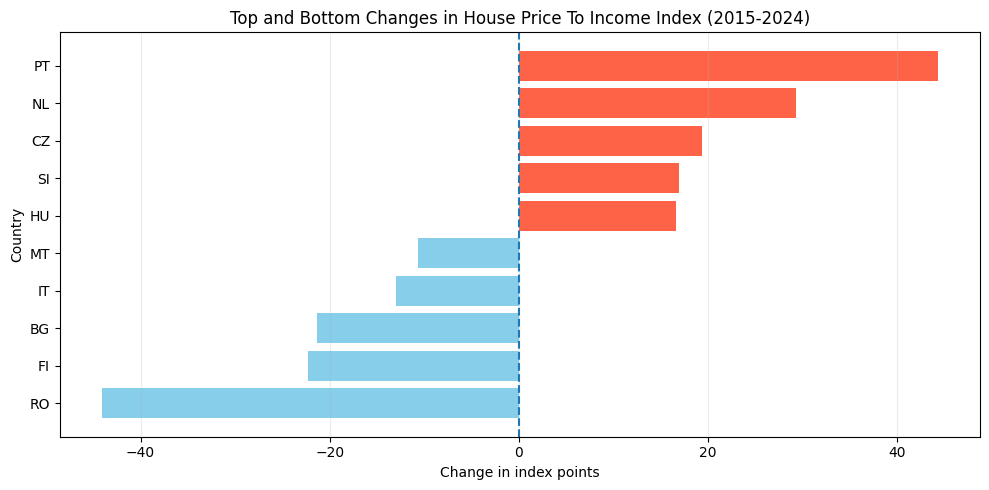

In [2020]:
main_column = 'house_price_to_income_index'
change_df_sorted = create_change(final_df, main_column)
bottom = change_df_sorted.head(5)
top= change_df_sorted.tail(5)
top_bottom = pd.concat([bottom, top])

colors =[]
for value in top_bottom['value_change']:
    if value > 0:
        colors.append('tomato')
    else:
        colors.append('skyblue')


plt.figure(figsize=(10, 5))
plt.barh(top_bottom['country'], top_bottom['value_change'], color=colors)
plt.axvline(0, linestyle='--')
plt.title(f'Top and Bottom Changes in {main_column.replace('_', ' ').title()} (2015-2024)')
plt.xlabel('Change in index points')
plt.ylabel('Country')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

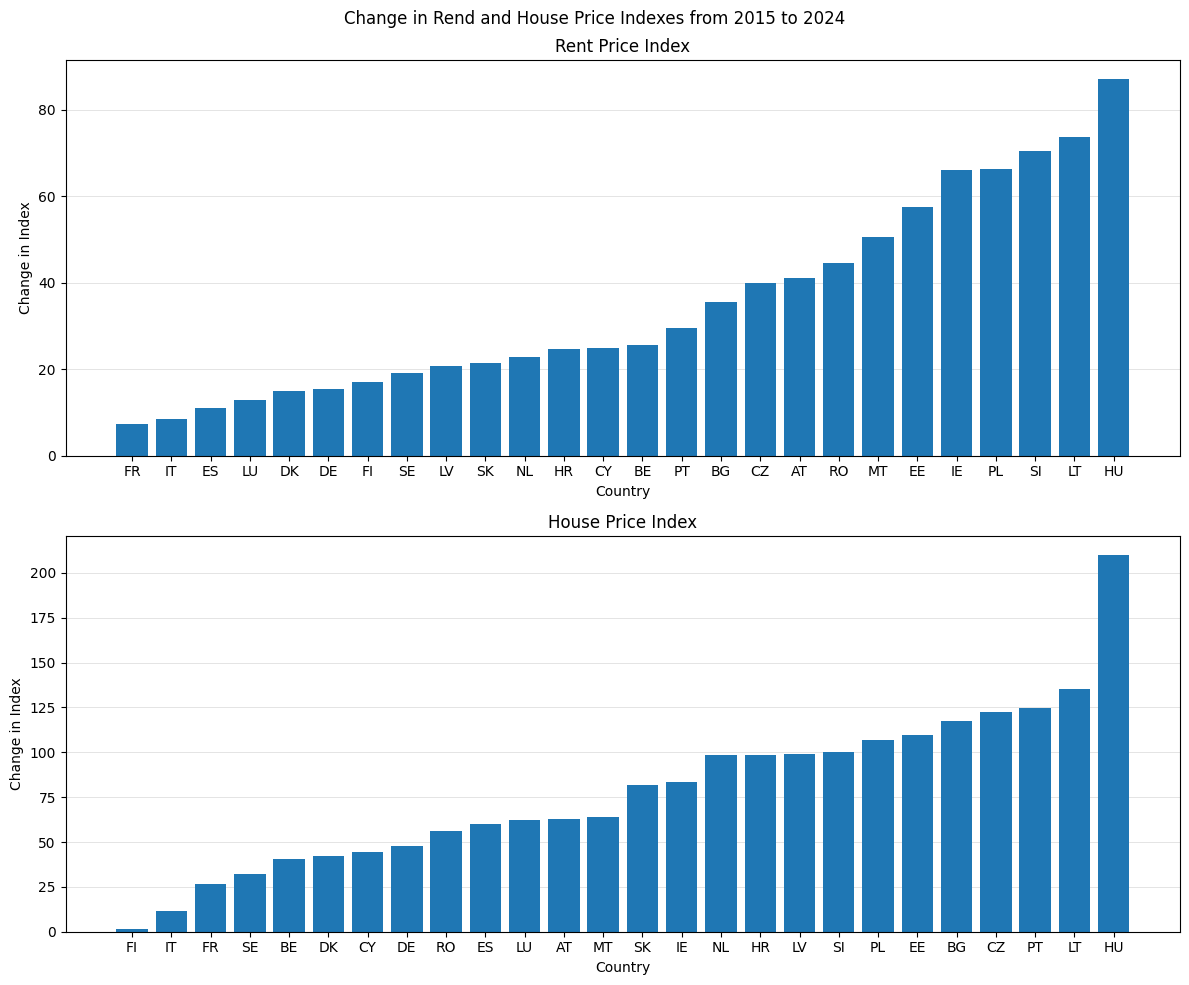

In [2021]:
rent_column = 'rent_price_index'
rent_change = create_change(final_df, rent_column)

house_column = 'house_price_index'
house_change = create_change(final_df, house_column)

fig, axes  = plt.subplots(2,1, figsize=(12,10))
ax = axes.flatten()
ax[0].bar(
    rent_change['country'],
    rent_change['value_change']
)

ax[0].set_title(rent_column.replace('_', ' ').title())
ax[0].set_xlabel('Country')
ax[0].set_ylabel('Change in Index')
ax[0].grid(axis='y', linewidth=0.6, alpha=0.4)
ax[0].set_axisbelow(True)

ax[1].bar(
    house_change['country'],
    house_change['value_change']
)

ax[1].set_title(house_column.replace('_', ' ').title())
ax[1].set_xlabel('Country')
ax[1].set_ylabel('Change in Index')
ax[1].grid(axis='y', linewidth=0.6, alpha=0.4)
ax[1].set_axisbelow(True)

plt.suptitle('Change in Rend and House Price Indexes from 2015 to 2024')
plt.tight_layout()
plt.show()


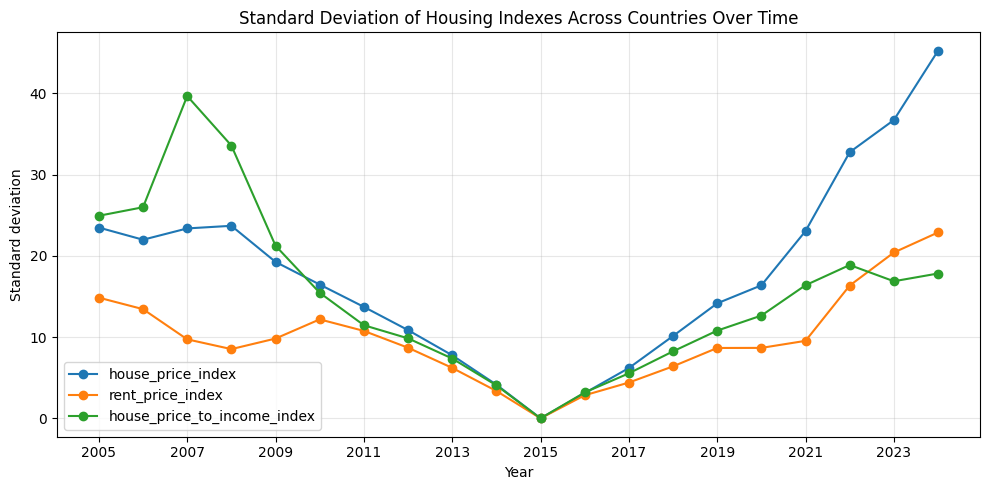

In [2022]:
main_variables = ['house_price_index', 'rent_price_index', 'house_price_to_income_index']
std_per_year = final_df.groupby('year')[main_variables].std()

plt.figure(figsize=(10, 5))
for column in main_variables_trends:
    plt.plot(std_per_year.index, std_per_year[column], marker='o', label=column)


plt.title('Standard Deviation of Housing Indexes Across Countries Over Time')
plt.xlabel('Year')
plt.ylabel('Standard deviation')
plt.xticks(sorted(final_df['year'].unique())[::2])

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Correlation Analysis

In [2023]:
corr_cols =  [col for col in final_raw_df.columns if col not in ['country', 'year', 'life_satisfaction']]

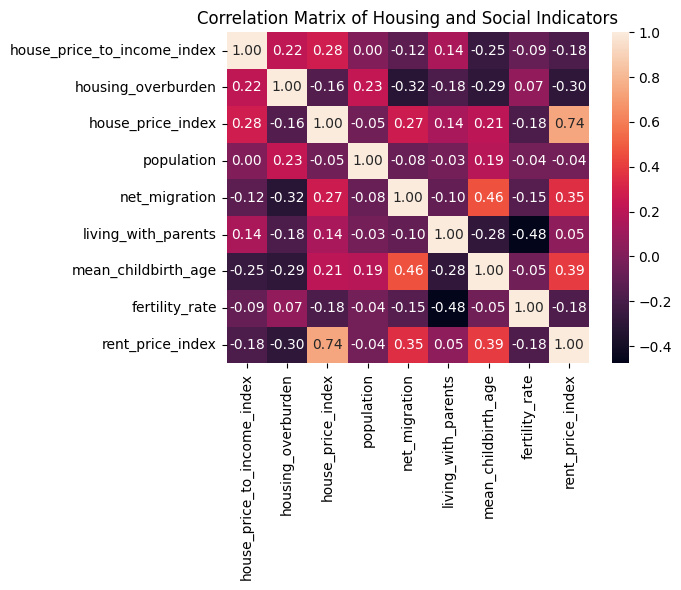

In [2024]:
corr = final_df[corr_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f'    
)

plt.title('Correlation Matrix of Housing and Social Indicators')
plt.tight_layout()
plt.show()

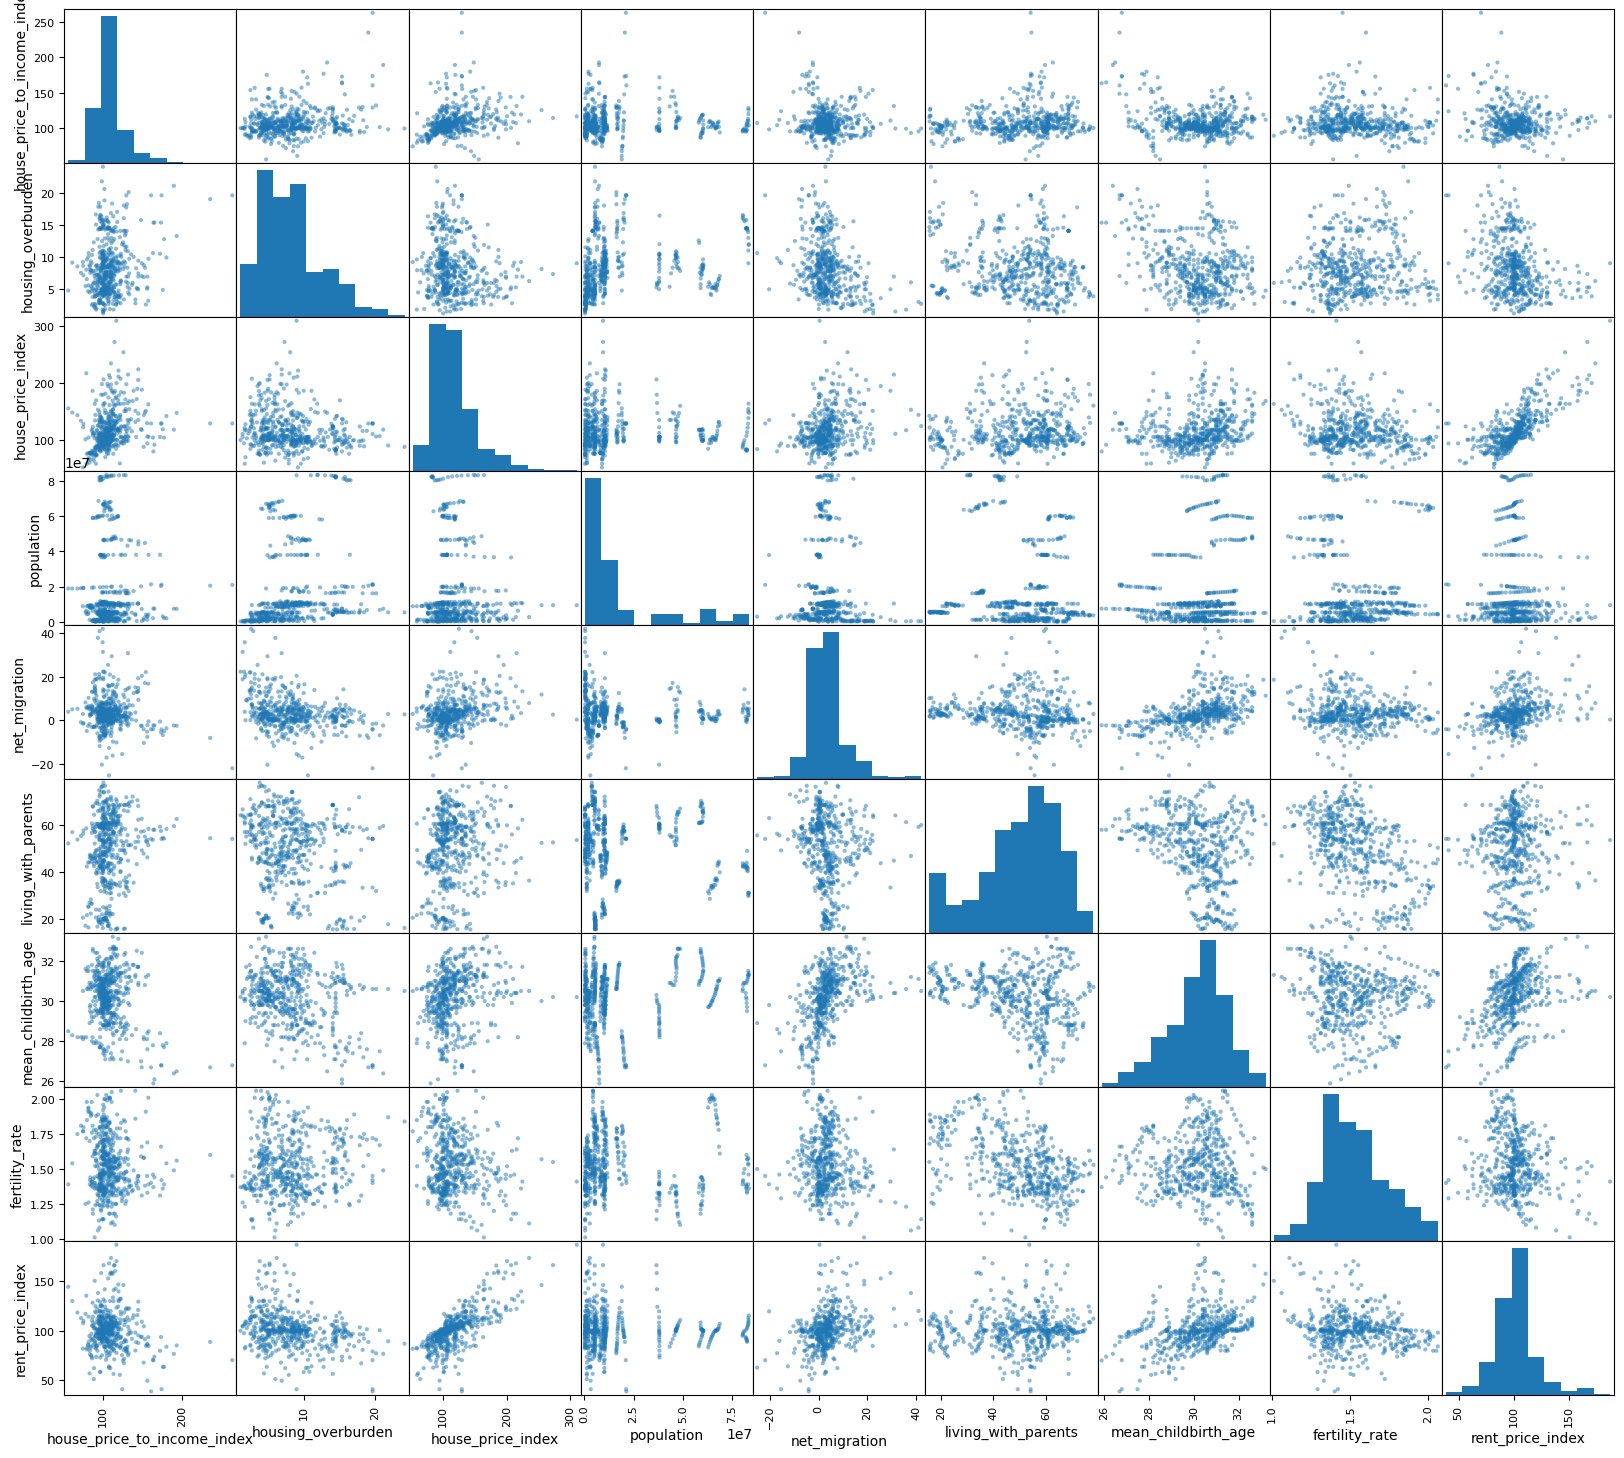

In [2025]:
pd.plotting.scatter_matrix(final_df[indicator_cols], figsize=(20, 18))
plt.show()

In [2026]:
corr_ranking = (
    corr
    .stack()
    .reset_index()
)
corr_ranking.columns = ['variable_1','variable_2','correlation']
corr_ranking = corr_ranking[corr_ranking['variable_1'] != corr_ranking['variable_2']]

corr_ranking['variables_pair'] = corr_ranking.apply(
    lambda row: tuple(sorted([row['variable_1'], row['variable_2']])), axis=1)
corr_ranking = corr_ranking.drop_duplicates('variables_pair')

corr_ranking = corr_ranking.sort_values(by='correlation', key=lambda x: abs(x), ascending=False)

corr_ranking = corr_ranking[['variable_1', 'variable_2', 'correlation']]
corr_ranking.head(10)

,variable_1,variable_2,correlation
26,house_price_index,rent_price_index,0.74
52,living_with_parents,fertility_rate,-0.48
42,net_migration,mean_childbirth_age,0.46
62,mean_childbirth_age,rent_price_index,0.39
44,net_migration,rent_price_index,0.35
13,housing_overburden,net_migration,-0.32
17,housing_overburden,rent_price_index,-0.30
15,housing_overburden,mean_childbirth_age,-0.29
51,living_with_parents,mean_childbirth_age,-0.28
2,house_price_to_income_index,house_price_index,0.28


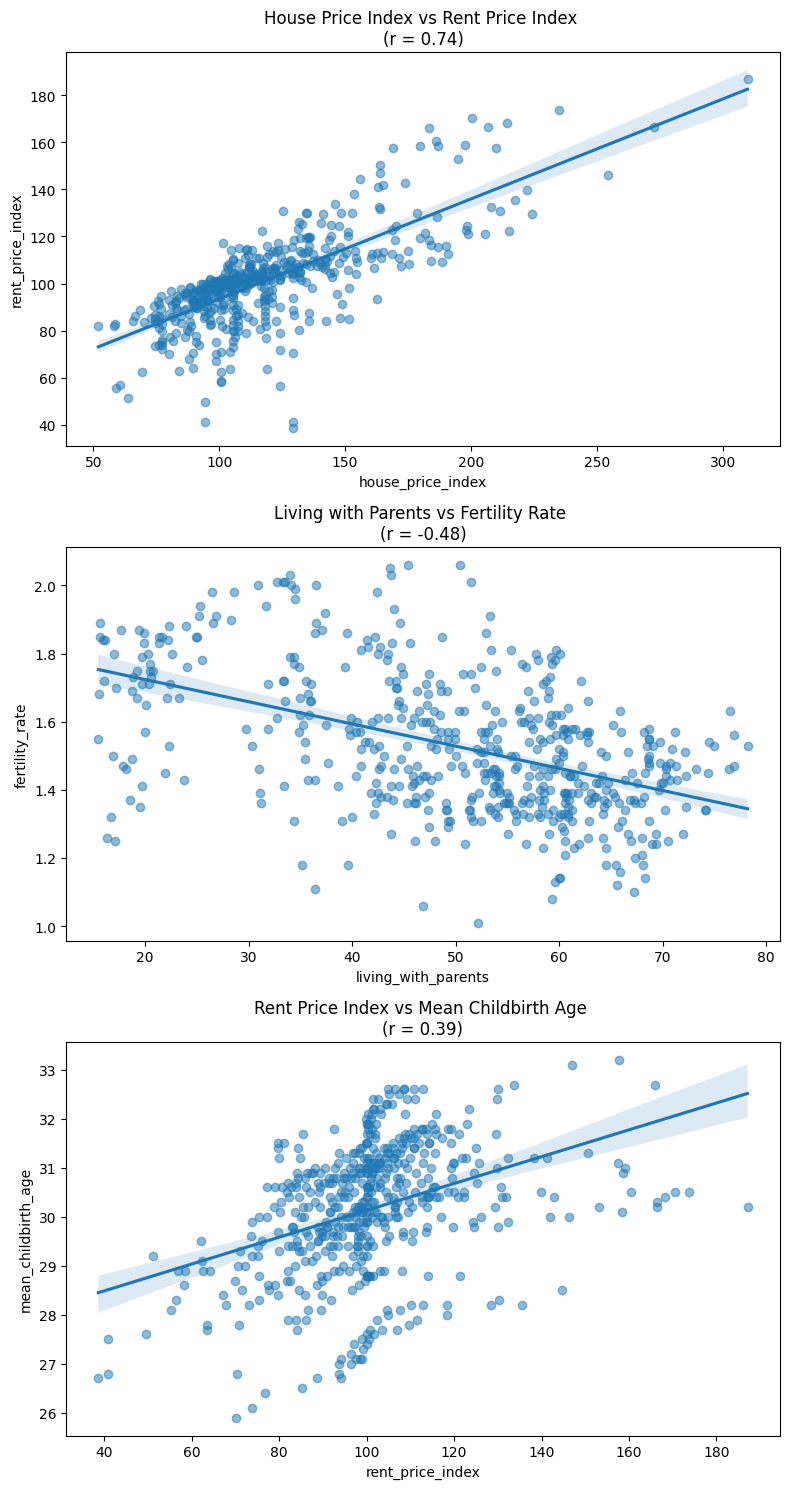

In [2027]:
fig, axes = plt.subplots(3, 1, figsize=(8, 15))

sns.regplot(
    data=final_df,
    x='house_price_index',
    y='rent_price_index',
    scatter_kws={'alpha':0.5},
    ax=axes[0]
)
axes[0].set_title('House Price Index vs Rent Price Index \n(r = 0.74)')

sns.regplot(
    data=final_df,
    x='living_with_parents',
    y='fertility_rate',
    scatter_kws={'alpha':0.5},
    ax=axes[1]
)

axes[1].set_title('Living with Parents vs Fertility Rate \n(r = -0.48)')

sns.regplot(
    data=final_df,
    x='rent_price_index',
    y='mean_childbirth_age',
    scatter_kws={'alpha': 0.5},
    ax=axes[2]
)
axes[2].set_title("Rent Price Index vs Mean Childbirth Age \n(r = 0.39)")

plt.tight_layout()
plt.show()

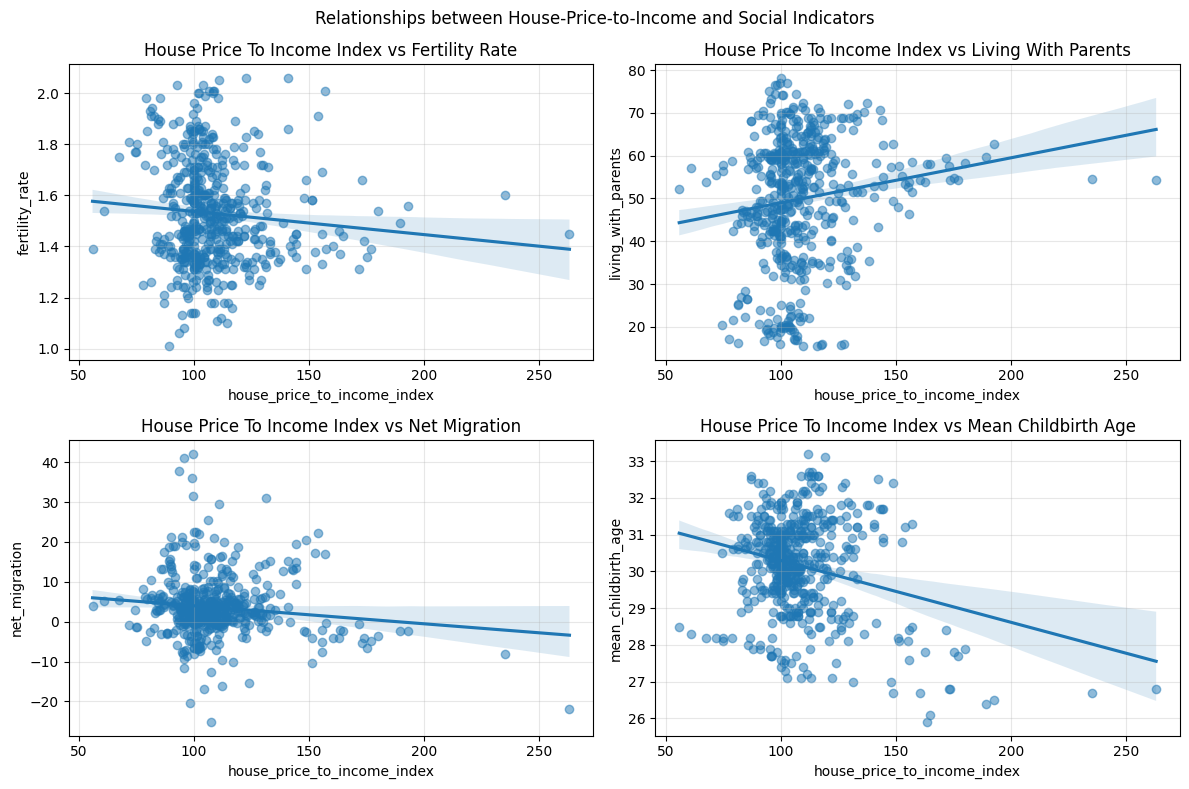

In [2033]:
pairs_for_scatterplot = [
    ('house_price_to_income_index', 'fertility_rate'),
    ('house_price_to_income_index', 'living_with_parents'),
    ('house_price_to_income_index', 'net_migration'),
    ('house_price_to_income_index', 'mean_childbirth_age')
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, (x, y) in enumerate(pairs_for_scatterplot):
    ax = axes[i]
    
    sns.regplot(data=final_df, x=x, y=y, ax=ax, scatter_kws={'alpha': 0.5})
    
    ax.set_title(f'{x.replace('_', ' ').title()} vs {y.replace('_', ' ').title()}')
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(alpha=0.3)

plt.suptitle('Relationships between House-Price-to-Income and Social Indicators')
plt.tight_layout()
plt.show()

### Outlier Analysis

In [ ]:
for_boxplots = [col for col in indicator_cols if col != 'population']


In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=final_df[for_boxplots])
plt.xticks(rotation=90, ha='right')
plt.title('Distribution of variables')
plt.show()

## Final Dataset Preparation

In [ ]:
final_df.to_csv('../data/final_dataset_draft.csv', index=False)